In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

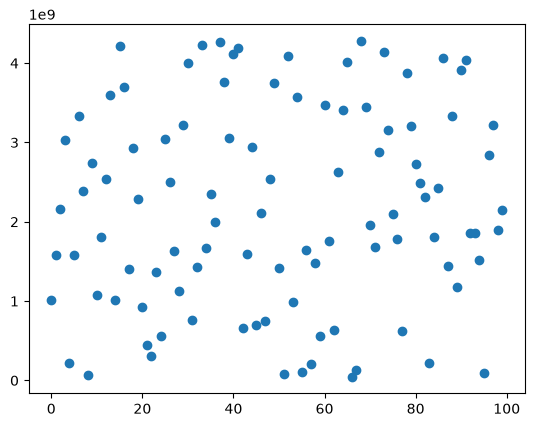

In [2]:
N = 100
a = 1664525
c = 1013904223
m = 4294967296
x = 1
results = []

for i in range (N):
    x = (a * x + c) % m
    results.append(x)

plt.plot(results, "o")

This is totally deterministic. Note certain conditions needs to be met in order to span the full (discrete) range (m).\
\
m and c cannot share any prime factors other than 1.\
\
(a - 1) must be divisible by every prime factor of m. (a - 1) must be divisible by 4 if m is divisible by 4.\
\
See below for what looks like a repeating pattern.

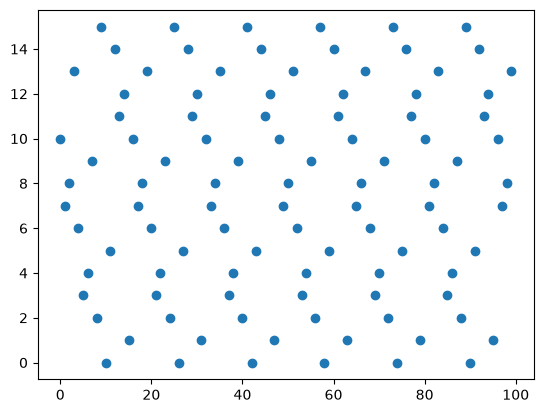

In [3]:
N = 100
a = 5
c = 5
m = 16
x = 1
results = []

for i in range (N):
    x = (a * x + c) % m
    results.append(x)

plt.plot(results, "o")

In [4]:
from random import randrange
dice_1 = randrange(6)
dice_2 = randrange(6)
print("Dice 1 gives:", dice_1)
print("Dice 2 gives:", dice_2)

Dice 1 gives: 5
Dice 2 gives: 3


In [5]:
N = 1000000
x = 0
y = 0

for i in range(N):
    dice_1 = randrange(7)
    dice_2 = randrange(7)
    
    if dice_1 == dice_2:
        x += 1
        if dice_2 == 6:
            y += 1

print("This is the percentage of times we get the same number:", x/1000000)
print("This is the percentage of times we get the number 6 twice:", y/1000000)

# note - use xrange(N) instead of range(N) in the for loop if you don't want to store N numbers in memory! (for large N)

This is the percentage of times we get the same number: 0.142617
This is the percentage of times we get the number 6 twice: 0.020383


In [6]:
N = 1000000
x = 0
y = 0

for i in range(N):
    dice_1 = randrange(7)
    dice_2 = randrange(7)
    
    if dice_1 == dice_2 == 6:
        x += 1

print("This is the percentage of times we get the number 6 twice:", x/1000000)

This is the percentage of times we get the number 6 twice: 0.02031


In [7]:
# start with N=100 just to make it interesting
N = 100
n = 100

# set a seed to generate the same sequence of "random" numbers...


#for i in range(N):
    

In [8]:
# how to use seed
random.seed(2)
['%.2f' % random.random() for i in range(10)]

['0.96',
 '0.95',
 '0.06',
 '0.08',
 '0.84',
 '0.74',
 '0.67',
 '0.31',
 '0.61',
 '0.61']

In [9]:
['%.2f' % random.random() for i in range(10)]

['0.58',
 '0.16',
 '0.43',
 '0.39',
 '0.72',
 '0.99',
 '0.95',
 '0.54',
 '0.44',
 '0.27']

In [10]:
random.seed(2)
['%.2f' % random.random() for i in range(10)]

['0.96',
 '0.95',
 '0.06',
 '0.08',
 '0.84',
 '0.74',
 '0.67',
 '0.31',
 '0.61',
 '0.61']

In [11]:
# see how that works?

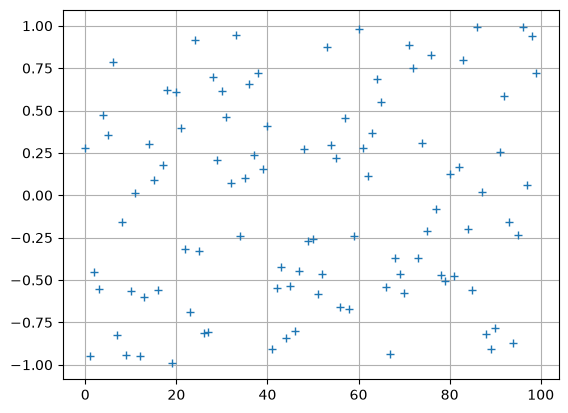

In [12]:
random.seed(42)
N = 100
x = range(N)
y = [random.uniform(-1, 1) for i in x]

plt.plot(x, y, '+')
plt.grid(True)

(array([ 94.,  92., 108.,  75., 114., 101., 109., 101., 100., 106.]),
 array([4.05939697e-04, 1.00356129e-01, 2.00306317e-01, 3.00256506e-01,
        4.00206695e-01, 5.00156884e-01, 6.00107073e-01, 7.00057262e-01,
        8.00007451e-01, 8.99957640e-01, 9.99907829e-01]),
 <BarContainer object of 10 artists>)

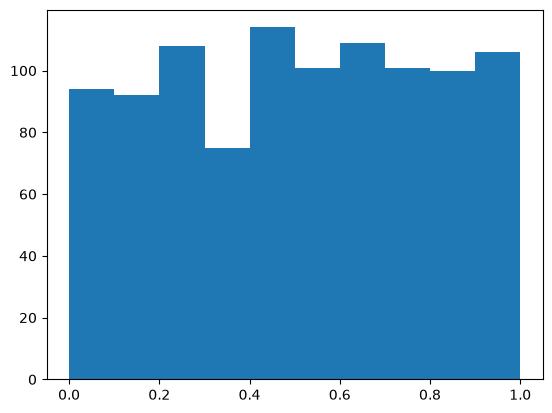

In [13]:
# plotting (histograms)
samples = [random.random() for i in range(1000)]
plt.hist(samples)

(array([  6.,  29.,  81., 186., 242., 220., 143.,  74.,  14.,   5.]),
 array([-28.27396462, -12.34000783,   3.59394896,  19.52790575,
         35.46186254,  51.39581933,  67.32977612,  83.26373291,
         99.1976897 , 115.13164649, 131.06560328]),
 <BarContainer object of 10 artists>)

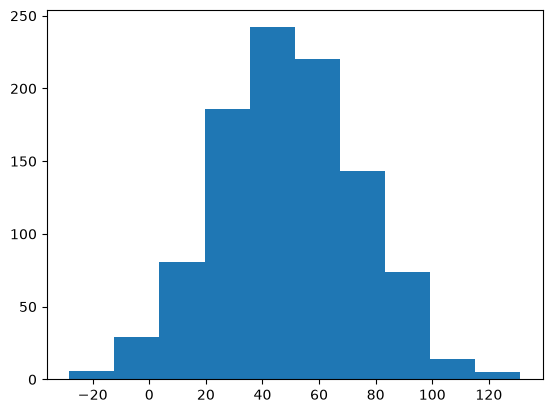

In [14]:
# just in case it comes in handy, you can do a normal distribution
# normal(mean, std deviation, size)
x = np.random.normal(50, 25, 1000)
plt.hist(x)

In [15]:
# using numpy, you select the range of numbers then how many you want
# no loops
samples_np = np.random.uniform(-1, 1, size=1000)
# or just one time
rand_np = np.random.uniform(-1,1)
rand_int = np.random.randint(0, N)
print(rand_int)
print(rand_np)
#print(samples_np)

# note = np.random.randint(a, b, N) does not include b, have to use np.random.randint(a, b+1, N)
# however, np.random.random_integers(a, b, N) does include b

50
0.11966144006765655


Thinking out loud: my main loop needs to have an if where it compares the probability (of moving boxes) to a random number. \
\
if np.random.randint(0, N) > (n / N): \
    change state from 0 to 1 \
\
So - how this all work when checking both sides? The particle chosen is obviously the array, particles[i]... \
\
so maybe, if i = 0, then use n / N as the probability \
\
and if i = 1 then use (N - n) / N as the probability to compare to. \
